# E1 · Laboratorio estadístico: pronóstico del costo de construcción — ObraPrecio

**Pregunta:** ¿se puede anticipar cuánto costará construir en Colima dentro de 1, 3, 6 y 12 meses, y con qué margen de error?

**Serie:** índice general de costo de construcción residencial de Colima (INEGI, INPP, base julio 2019 = 100), mensual, de enero de 2004 a octubre de 2026 (274 meses). Sale de la capa oro (`data/oro/obraprecio_ciudad_mensual.csv`), ya validada por la puerta de calidad. Se repite el ejercicio con el índice Nacional para comprobar que las conclusiones no dependen de una sola ciudad.

| Sección | Criterio de la rúbrica |
|---|---|
| 1 | Caracterización de la serie |
| 2 | Estacionariedad, ACF y PACF |
| 3 | Cuatro modelos: suavizamiento simple, Holt, Holt-Winters y ARIMA/SARIMA |
| 4 | Evaluación con MAE, RMSE y MAPE |
| 5 | Diagnóstico de residuos (Ljung-Box) |
| 6 | Pronóstico y conclusiones |

El código de los modelos está en `laboratorio/modelos.py` y tiene sus pruebas en `tests/test_laboratorio.py`.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.stattools import acf, pacf

RAIZ = Path.cwd() if (Path.cwd() / "laboratorio").exists() else Path.cwd().parents[1]
sys.path.insert(0, str(RAIZ))
from laboratorio import modelos as M

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170); pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
COLOR = {"ses": "#2a78d6", "holt": "#eb6834", "holt_winters": "#1baf7a", "sarima": "#6250d6", "ingenuo": "#898781", "deriva": "#898781"}
ESTILO = {"ingenuo": ":", "deriva": "--"}
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "text.color": "#0b0b0b", "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 9.5, "lines.linewidth": 2, "figure.dpi": 110})

tabla = pd.read_csv(RAIZ / "data/oro/obraprecio_ciudad_mensual.csv", parse_dates=["fecha"])
y = M.serie_mensual(tabla, "colima"); nac = M.serie_mensual(tabla, "nacional")
H = 12; ent, pru = y.iloc[:-H], y.iloc[-H:]
print(f"Colima: {len(y)} meses, {y.index[0]:%Y-%m} a {y.index[-1]:%Y-%m} | entrenamiento hasta {ent.index[-1]:%Y-%m} ({len(ent)}) | prueba {pru.index[0]:%Y-%m} a {pru.index[-1]:%Y-%m} ({H})")

Colima: 274 meses, 2004-01 a 2026-10 | entrenamiento hasta 2025-10 (262) | prueba 2025-11 a 2026-10 (12)


## 1. Caracterización de la serie

In [2]:
var_m = y.pct_change() * 100; var_a = y.pct_change(12) * 100
desc = pd.DataFrame({"índice": y.describe(), "variación mensual %": var_m.describe(), "variación anual %": var_a.describe()}).T
desc["asimetría"] = [y.skew(), var_m.skew(), var_a.skew()]; desc["curtosis"] = [y.kurt(), var_m.kurt(), var_a.kurt()]
display(desc)
stl = M.descomponer(y); fuerza = M.fuerza_tendencia_estacionalidad(stl); fz_nac = M.fuerza_tendencia_estacionalidad(M.descomponer(nac))
print(f"Fuerza de la tendencia: Colima {fuerza['tendencia']:.3f}, Nacional {fz_nac['tendencia']:.3f} | fuerza de la estacionalidad: Colima {fuerza['estacionalidad']:.3f}, Nacional {fz_nac['estacionalidad']:.3f}  (0 = nula, 1 = total)")
print(f"Crecimiento total {y.index[0]:%Y-%m} a {y.index[-1]:%Y-%m}: {(y.iloc[-1] / y.iloc[0] - 1) * 100:.0f} % | promedio anual compuesto: {((y.iloc[-1] / y.iloc[0]) ** (12 / (len(y) - 1)) - 1) * 100:.2f} %")

,count,mean,std,min,25%,50%,75%,max,asimetría,curtosis
índice,274.000,89.209,35.514,43.961,59.892,73.933,113.971,163.155,0.714,-0.859
variación mensual %,273.000,0.489,1.232,-2.360,-0.105,0.210,0.854,8.302,2.599,11.997
variación anual %,262.000,5.708,4.829,-5.146,2.318,5.220,8.116,19.057,0.533,-0.011


Fuerza de la tendencia: Colima 0.998, Nacional 0.998 | fuerza de la estacionalidad: Colima 0.209, Nacional 0.158  (0 = nula, 1 = total)
Crecimiento total 2004-01 a 2026-10: 271 % | promedio anual compuesto: 5.93 %


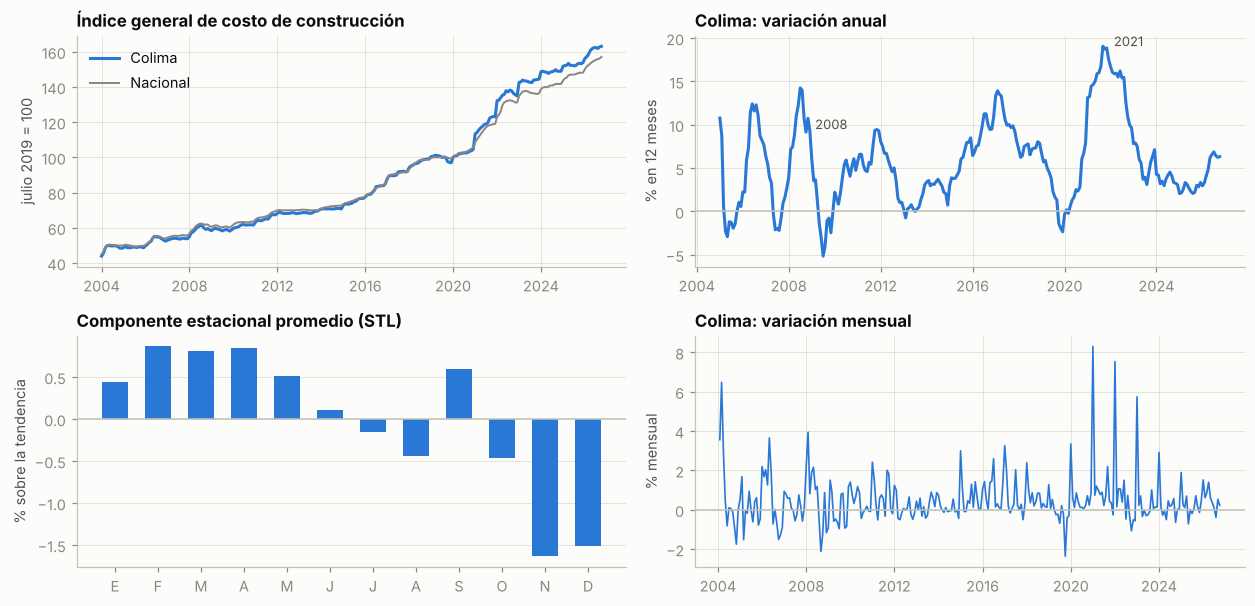

Componente estacional promedio por mes (%): {1: 0.44, 2: 0.86, 3: 0.81, 4: 0.85, 5: 0.52, 6: 0.11, 7: -0.15, 8: -0.44, 9: 0.59, 10: -0.46, 11: -1.63, 12: -1.51}


In [3]:
fig, axs = plt.subplots(2, 2, figsize=(11.5, 5.6))
ax = axs[0, 0]; ax.plot(y, color="#2a78d6", label="Colima"); ax.plot(nac, color="#898781", lw=1.3, label="Nacional")
ax.set(title="Índice general de costo de construcción", ylabel="julio 2019 = 100"); ax.legend(frameon=False)
ax = axs[0, 1]; ax.plot(var_a, color="#2a78d6"); ax.axhline(0, color="#c3c2b7", lw=1); ax.set(title="Colima: variación anual", ylabel="% en 12 meses")
for f, txt in (("2008-10-01", "2008"), ("2021-10-01", "2021")): ax.annotate(txt, (pd.Timestamp(f), var_a[f]), textcoords="offset points", xytext=(6, 2), fontsize=8.5, color="#52514e")
ax = axs[1, 0]; est = (np.exp(stl.seasonal) - 1) * 100; mes = est.groupby(est.index.month).mean()
ax.bar(mes.index, mes.values, color="#2a78d6", width=0.62); ax.axhline(0, color="#c3c2b7", lw=1)
ax.set(title="Componente estacional promedio (STL)", ylabel="% sobre la tendencia", xticks=range(1, 13), xticklabels=list("EFMAMJJASOND")); ax.grid(axis="x", visible=False)
ax = axs[1, 1]; ax.plot(var_m, color="#2a78d6", lw=1.1); ax.axhline(0, color="#c3c2b7", lw=1); ax.set(title="Colima: variación mensual", ylabel="% mensual")
plt.tight_layout(); plt.show()
print("Componente estacional promedio por mes (%):", mes.round(2).to_dict())

**Lectura.**

- **Tendencia:** domina por completo (fuerza cercana a 1). El índice más que se triplica entre 2004 y 2026 (crece 271 %, casi 6 % anual compuesto); un modelo sin tendencia se va a quedar corto en horizontes largos.
- **Estacionalidad:** débil según la descomposición STL (fuerza de 0.2 en Colima y 0.16 en el Nacional), pero con una forma muy concreta: el índice queda por encima de su tendencia de enero a mayo y por debajo en noviembre y diciembre, con una amplitud de 1 a 2 puntos porcentuales. En la gráfica del nivel se ve la causa: **el índice da un escalón cada enero**, más marcado desde 2021.
- **Choques:** la variación mensual no tiene varianza constante. Hay episodios de alzas fuertes (2004, 2008, 2021 y 2022) seguidos de periodos tranquilos e incluso de bajas (variación anual negativa en 2009 y entre 2019 y 2020). La curtosis alta de la variación mensual lo confirma: colas más pesadas que una normal.
- **Consecuencia para modelar:** se trabaja en logaritmos (los cambios son proporcionales), hace falta diferenciar para quitar la tendencia y el modelo debe poder anticipar el escalón de enero.

## 2. Estacionariedad, ACF y PACF

In [4]:
ly = np.log(y)
pruebas = pd.DataFrame([M.pruebas_estacionariedad(y, "índice (nivel)"), M.pruebas_estacionariedad(ly, "log(índice)"),
    M.pruebas_estacionariedad(ly.diff(), "Δ log (variación mensual)"), M.pruebas_estacionariedad(ly.diff().diff(12), "Δ Δ12 log")]).set_index("serie")
display(pruebas)

,n,ADF,p ADF,KPSS,p KPSS,lectura
serie,,,,,,
índice (nivel),274,0.999,0.994,2.414,0.010,no estacionaria
log(índice),274,0.170,0.971,2.541,0.010,no estacionaria
Δ log (variación mensual),273,-4.204,0.001,0.082,0.100,estacionaria
Δ Δ12 log,261,-7.187,0.000,0.035,0.100,estacionaria


Se leen dos pruebas con hipótesis opuestas: **ADF** (H0: hay raíz unitaria, no es estacionaria) y **KPSS** (H0: es estacionaria).

- En **nivel** las dos coinciden: ADF no rechaza y KPSS rechaza. La serie **no es estacionaria**.
- Con **una diferencia del logaritmo** (la variación mensual) las dos coinciden en que **ya es estacionaria**: ADF rechaza la raíz unitaria y KPSS no rechaza la estacionariedad.
- La diferencia estacional adicional no hace falta para lograr estacionariedad. Por eso se fija **d = 1 y D = 0**, y la dependencia estacional se modela con términos AR y MA estacionales.

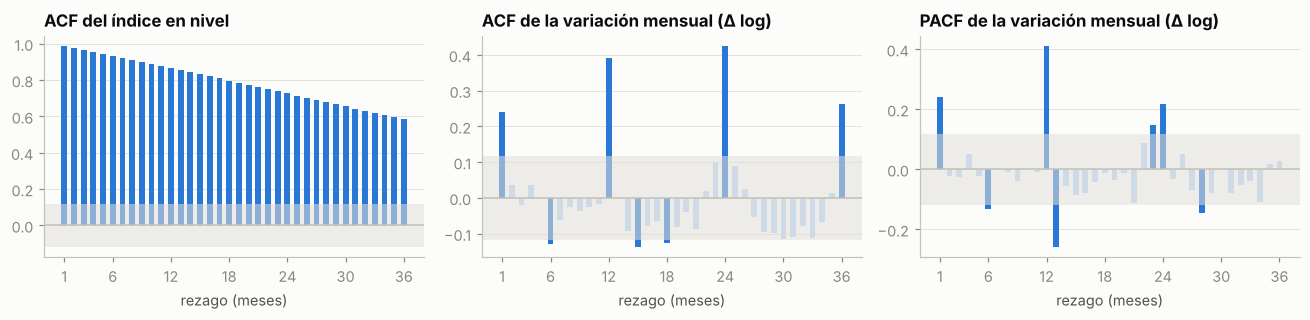

Banda de significancia (95 %): ±0.119. Barras oscuras = fuera de la banda.
ACF  significativa en rezagos: [1, 6, 12, 15, 18, 24, 36]
PACF significativa en rezagos: [1, 6, 12, 13, 23, 24, 28]
ACF(1) = 0.240 | ACF(12) = 0.391 | PACF(1) = 0.240 | PACF(2) = -0.022


In [5]:
def barras(ax, vals, n, titulo):
    k = np.arange(1, len(vals)); lim = 1.96 / np.sqrt(n)
    ax.bar(k, vals[1:], color=["#2a78d6" if abs(v) > lim else "#b7d3f6" for v in vals[1:]], width=0.6)
    ax.axhspan(-lim, lim, color="#e1e0d9", alpha=0.55, lw=0); ax.axhline(0, color="#c3c2b7", lw=1)
    ax.set(title=titulo, xlabel="rezago (meses)", xticks=[1, 6, 12, 18, 24, 30, 36]); ax.grid(axis="x", visible=False)
d1 = ly.diff().dropna(); fig, axs = plt.subplots(1, 3, figsize=(12, 3))
barras(axs[0], acf(y, nlags=36), len(y), "ACF del índice en nivel")
barras(axs[1], acf(d1, nlags=36), len(d1), "ACF de la variación mensual (Δ log)")
barras(axs[2], pacf(d1, nlags=36, method="ywm"), len(d1), "PACF de la variación mensual (Δ log)")
plt.tight_layout(); plt.show()
a, pa = acf(d1, nlags=36), pacf(d1, nlags=36, method="ywm"); lim = 1.96 / np.sqrt(len(d1))
print(f"Banda de significancia (95 %): ±{lim:.3f}. Barras oscuras = fuera de la banda.")
print("ACF  significativa en rezagos:", [k for k in range(1, 37) if abs(a[k]) > lim])
print("PACF significativa en rezagos:", [k for k in range(1, 37) if abs(pa[k]) > lim])
print(f"ACF(1) = {a[1]:.3f} | ACF(12) = {a[12]:.3f} | PACF(1) = {pa[1]:.3f} | PACF(2) = {pa[2]:.3f}")

**Lectura.**

- La ACF en nivel decae muy lento: firma clásica de una serie con tendencia.
- En la variación mensual, ACF y PACF son significativas en el rezago 1 (0.24) y la PACF del rezago 2 es prácticamente cero: eso sugiere un componente **de orden bajo, AR(1) o MA(1)**. Un mes de alza tiende a ir seguido de otro mes de alza.
- Hay picos en los rezagos 6, 12 y 24, y **la ACF del rezago 12 (0.39) es mayor que la del rezago 1**: la dependencia anual es más importante de lo que sugería la fuerza estacional de la STL. Es el escalón de enero. Se permiten términos estacionales (P, Q ≤ 1).

Candidatos: (p, 1, q)(P, 0, Q)₁₂ con p, q ≤ 2. El orden final se elige por AIC en la sección 3.

## 3. Los cuatro modelos

Todos se ajustan **solo con el entrenamiento** (hasta octubre de 2025). Los últimos 12 meses se guardan para la prueba.

| Modelo | Qué captura | Parámetros |
|---|---|---|
| Suavizamiento exponencial simple | Nivel | α |
| Holt | Nivel y tendencia lineal | α, β |
| Holt-Winters | Nivel, tendencia y estacionalidad multiplicativa de 12 meses | α, β, γ |
| SARIMA sobre log(índice) | Dependencia entre meses, deriva y estacionalidad | órdenes por AIC |
| *Ingenuo y deriva* | *Referencias: "seguirá igual" y "seguirá creciendo al ritmo de los últimos 5 años"* | |

In [6]:
orden, estacional, busqueda = M.elegir_sarima(ent)
print(f"SARIMA elegido por AIC: {orden}{estacional[:3]}[12] con constante (deriva)")
display(busqueda.head(5))
ajustes = {n: M.ajustar(n, ent, (orden, estacional)) for n in M.MODELOS}
filas = []
for n in ("ses", "holt", "holt_winters", "sarima"):
    par = {k: (f"{v:.4f}" if isinstance(v, (float, np.floating)) else str(v)) for k, v in ajustes[n]["parametros"].items()}
    filas.append({"modelo": M.ETIQUETA[n], "parámetros estimados": ", ".join(f"{k} = {v}" for k, v in par.items())})
pd.set_option("display.max_colwidth", 90); display(pd.DataFrame(filas).set_index("modelo"))

SARIMA elegido por AIC: (1, 1, 0)(1, 0, 1)[12] con constante (deriva)


,orden,estacional,AIC,BIC
0,"(1, 1, 0)","(1, 0, 1)","-1,651.018","-1,633.195"
1,"(1, 1, 1)","(1, 0, 1)","-1,649.569","-1,628.182"
2,"(0, 1, 2)","(1, 0, 1)","-1,648.496","-1,627.109"
3,"(0, 1, 1)","(1, 0, 1)","-1,647.974","-1,630.151"
4,"(2, 1, 1)","(1, 0, 1)","-1,647.144","-1,622.192"


,parámetros estimados
modelo,
Suavizamiento simple,alfa = 1.0000
Holt,"alfa = 1.0000, beta = 0.0211"
Holt-Winters,"alfa = 1.0000, beta = 0.1227, gamma = 0.0000"
SARIMA,"orden = (1, 1, 0), estacional = (1, 0, 1), AIC = -1651.0176"


**Lectura de los parámetros.**

- **α ≈ 1 en los tres suavizamientos.** El modelo le cree casi por completo al último dato. Con α = 1 el suavizamiento simple se vuelve idéntico al modelo ingenuo: su pronóstico es una línea plana en el último valor. Esto es coherente con una serie que se comporta como caminata con deriva.
- **γ ≈ 0 en Holt-Winters.** El patrón estacional no se actualiza: se estima una sola vez y se queda fijo, lo esperable con estacionalidad débil y estable.
- **SARIMA** elige un AR(1) más un término estacional, lo mismo que sugerían la ACF y la PACF.

## 4. Evaluación: MAE, RMSE y MAPE

### 4.1 Retención de los últimos 12 meses

,MAE,RMSE,MAPE_pct,MAPE % (Nacional)
modelo,,,,
Deriva (referencia),1.118,1.402,0.698,0.499
SARIMA,1.269,1.429,0.791,0.326
Holt-Winters,2.040,2.368,1.265,0.868
Holt,2.676,2.990,1.661,1.906
Ingenuo (último valor),6.152,7.010,3.811,3.245
Suavizamiento simple,6.152,7.010,3.811,3.245


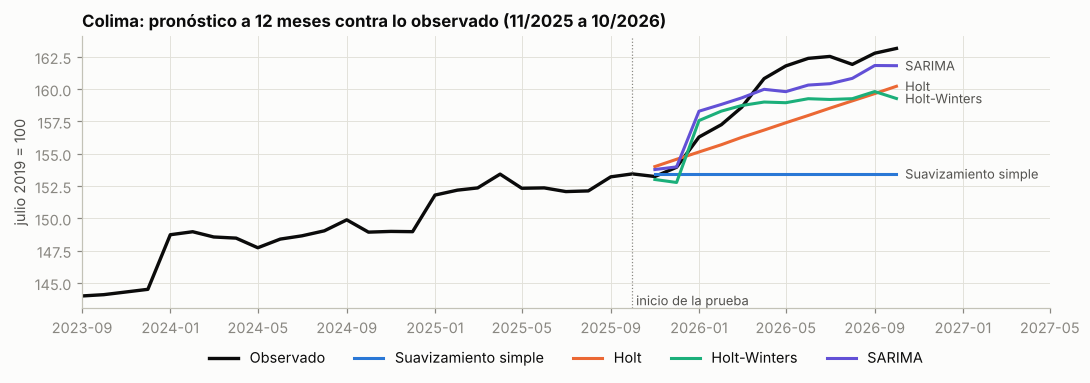

In [7]:
ret, pronos = M.evaluar_retencion(y, H, (orden, estacional))
ret_nac_orden = M.elegir_sarima(nac.iloc[:-H])[:2]; ret_nac, _ = M.evaluar_retencion(nac, H, ret_nac_orden)
t = ret.assign(modelo=ret.modelo.map(M.ETIQUETA)).set_index("modelo"); t["MAPE % (Nacional)"] = ret_nac.MAPE_pct.to_numpy()
display(t.sort_values("RMSE"))
fig, ax = plt.subplots(figsize=(10, 3.6)); ini = pru.index[0] - pd.DateOffset(months=26); ax.plot(y[ini:], color="#0b0b0b", lw=2.2, label="Observado")
ax.axvline(ent.index[-1], color="#898781", lw=0.8, ls=":"); ax.text(ent.index[-1], ax.get_ylim()[0], " inicio de la prueba", fontsize=8.5, color="#52514e", va="bottom")
for n in ("ses", "holt", "holt_winters", "sarima"):
    p = pronos[n]; ax.plot(p, color=COLOR[n], label=M.ETIQUETA[n]); ax.text(p.index[-1] + pd.Timedelta(days=12), p.iloc[-1], M.ETIQUETA[n], color="#52514e", fontsize=8.5, va="center")
ax.set(title=f"Colima: pronóstico a 12 meses contra lo observado ({pru.index[0]:%m/%Y} a {pru.index[-1]:%m/%Y})", ylabel="julio 2019 = 100", xlim=(ini, pru.index[-1] + pd.DateOffset(months=7)))
ax.legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1)); plt.tight_layout(); plt.show()

En esta ventana, en Colima quedan prácticamente empatados la referencia de deriva y SARIMA (MAPE de 0.70 % y 0.79 %), después Holt-Winters y Holt; el ingenuo y el suavizamiento simple son los peores (3.8 %) porque el índice subió todo el año y ellos pronostican una línea plana. En el Nacional gana SARIMA. **Una sola ventana de 12 meses no alcanza para decidir**: aquí una regla tan simple como la deriva sale primera y, como se ve en seguida, es la peor cuando se evalúa en muchas fechas.

### 4.2 Validación con origen móvil (la que decide)

Se repite el pronóstico desde **36 fechas de origen distintas** (los últimos tres años). En cada una el modelo se reajusta solo con lo conocido hasta ese mes y se mide el error a 1, 3, 6 y 12 meses. Son 36 pronósticos por modelo y horizonte en lugar de uno.

In [8]:
vc = M.validacion_origen_movil(y, horizontes=(1, 3, 6, 12), origenes=36, sarima=(orden, estacional)); res = M.resumen_validacion(vc)
print(f"Orígenes: {vc.origen.min():%Y-%m} a {vc.origen.max():%Y-%m} | pronósticos por modelo y horizonte: {vc.groupby(['modelo', 'h']).size().iloc[0]}")
for met in ("MAE", "RMSE", "MAPE_pct"):
    t = res.pivot(index="modelo", columns="h", values=met).rename(index=M.ETIQUETA); t.columns = [f"{met.replace('_pct', ' %')} h={h}" for h in t.columns]; display(t.sort_values(t.columns[0]))
mejor = res.loc[res.groupby("h").MAPE_pct.idxmin(), ["h", "modelo", "MAPE_pct"]].assign(modelo=lambda d: d.modelo.map(M.ETIQUETA)); print("Mejor modelo por horizonte (MAPE):"); display(mejor.set_index("h"))
vc_nac = M.validacion_origen_movil(nac, horizontes=(1, 3, 6, 12), origenes=36, sarima=ret_nac_orden); res_nac = M.resumen_validacion(vc_nac)

Orígenes: 2022-11 a 2025-10 | pronósticos por modelo y horizonte: 36


,MAE h=1,MAE h=3,MAE h=6,MAE h=12
modelo,,,,
SARIMA,0.687,1.663,2.655,5.040
Ingenuo (último valor),0.819,1.776,2.713,5.871
Suavizamiento simple,0.819,1.776,2.713,5.871
Holt-Winters,0.929,1.873,2.130,3.595
Holt,1.039,2.065,2.688,3.696
Deriva (referencia),1.191,2.462,3.724,6.282


,RMSE h=1,RMSE h=3,RMSE h=6,RMSE h=12
modelo,,,,
SARIMA,0.982,2.023,3.230,5.474
Holt-Winters,1.308,2.251,2.734,4.348
Holt,1.597,2.474,3.211,4.031
Suavizamiento simple,1.643,2.679,3.650,6.289
Ingenuo (último valor),1.643,2.679,3.650,6.289
Deriva (referencia),1.660,2.827,4.200,6.711


,MAPE % h=1,MAPE % h=3,MAPE % h=6,MAPE % h=12
modelo,,,,
SARIMA,0.465,1.122,1.785,3.326
Ingenuo (último valor),0.558,1.200,1.801,3.814
Suavizamiento simple,0.558,1.200,1.801,3.814
Holt-Winters,0.633,1.268,1.429,2.342
Holt,0.710,1.403,1.809,2.427
Deriva (referencia),0.811,1.667,2.497,4.118


Mejor modelo por horizonte (MAPE):


,modelo,MAPE_pct
h,,
1,SARIMA,0.465
3,SARIMA,1.122
6,Holt-Winters,1.429
12,Holt-Winters,2.342


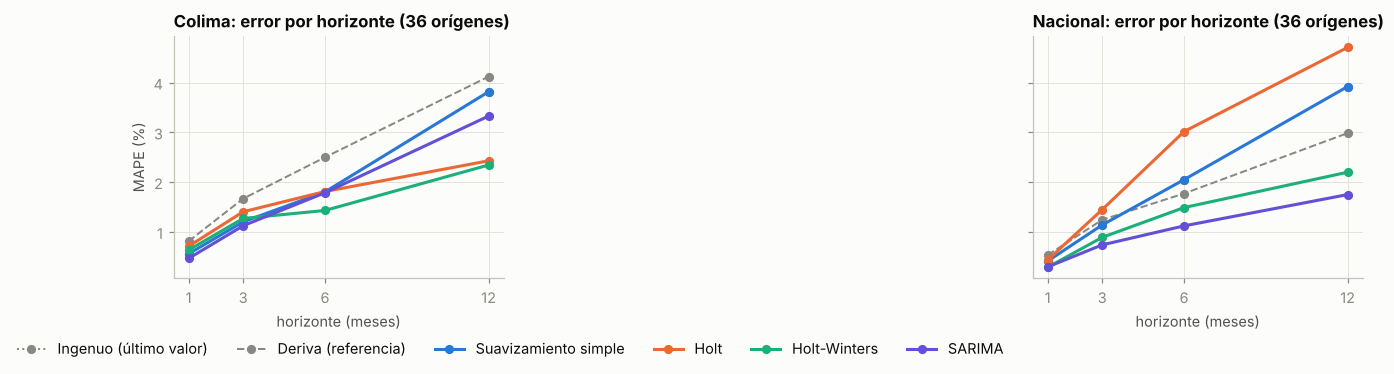

MAPE % del índice Nacional:


h,1,3,6,12
modelo,,,,
Deriva (referencia),0.533,1.242,1.769,2.983
Holt,0.435,1.447,3.014,4.705
Holt-Winters,0.288,0.889,1.487,2.197
Ingenuo (último valor),0.413,1.138,2.048,3.918
SARIMA,0.295,0.737,1.119,1.748
Suavizamiento simple,0.413,1.138,2.048,3.918


Sesgo (error medio, real - pronóstico) en Colima:


h,1,3,6,12
modelo,,,,
Deriva (referencia),-0.488,-1.551,-3.272,-6.282
Holt,-0.223,-0.738,-1.588,-2.671
Holt-Winters,-0.029,-0.219,-0.506,-0.394
Ingenuo (último valor),0.489,1.398,2.683,5.871
SARIMA,-0.303,-1.174,-2.556,-4.233
Suavizamiento simple,0.489,1.398,2.683,5.871


In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.6), sharey=True)
for ax, r, tit in ((axs[0], res, "Colima"), (axs[1], res_nac, "Nacional")):
    for n in M.MODELOS:
        d = r[r.modelo == n]; ax.plot(d.h, d.MAPE_pct, color=COLOR[n], ls=ESTILO.get(n, "-"), lw=1.3 if n in ESTILO else 2, marker="o", ms=5, label=M.ETIQUETA[n])
    ax.set(title=f"{tit}: error por horizonte (36 orígenes)", xlabel="horizonte (meses)", xticks=[1, 3, 6, 12])
axs[0].set_ylabel("MAPE (%)"); axs[0].legend(frameon=False, ncol=6, loc="upper center", bbox_to_anchor=(1.02, -0.2)); plt.tight_layout(); plt.show()
print("MAPE % del índice Nacional:"); display(res_nac.pivot(index="modelo", columns="h", values="MAPE_pct").rename(index=M.ETIQUETA))
print("Sesgo (error medio, real - pronóstico) en Colima:"); display(res.pivot(index="modelo", columns="h", values="sesgo").rename(index=M.ETIQUETA))

**Lectura.**

- **A 1 y 3 meses gana SARIMA** en Colima, con un MAPE de 0.47 % a un mes y 1.12 % a tres. Es el horizonte que le sirve a quien está cotizando una obra.
- **A 6 y 12 meses gana Holt-Winters** (1.43 % y 2.34 %), con Holt muy cerca a 12 meses (2.43 %). SARIMA se queda en 3.3 % a un año.
- **El suavizamiento simple es idéntico al ingenuo** en todos los horizontes (consecuencia de α ≈ 1): no aporta nada sobre repetir el último valor.
- **La referencia de deriva es la peor en Colima en todos los horizontes**, aunque ganó en la ventana única de 4.1.
- **Holt es inestable:** aceptable en Colima, pero en el Nacional es el peor a 6 y 12 meses. Extrapola como recta la tendencia reciente, y después de un choque esa recta se dispara.
- En el **Nacional** SARIMA es el mejor a 3, 6 y 12 meses y empata con Holt-Winters a un mes.
- El error crece con el horizonte en todos los modelos, como debe ser.
- **Sesgo:** a 12 meses SARIMA pronostica de más (error medio de −4.2 puntos del índice) y la deriva todavía más (−6.3); Holt-Winters casi no tiene sesgo (−0.4). La validación cubre de fines de 2022 a 2025, la desaceleración que siguió al alza de 2021 y 2022: los modelos con deriva constante tardan en dejar de extrapolar el ritmo alto.

## 5. Diagnóstico de residuos

Un modelo bien especificado deja residuos sin estructura: media cero y sin autocorrelación (**ruido blanco**). Se prueba con **Ljung-Box** a 12 y 24 rezagos (H0: no hay autocorrelación; se corrigen los grados de libertad por los parámetros estimados) y normalidad con Jarque-Bera. Los residuos de SARIMA están en escala logarítmica; los demás, en puntos del índice.

,n,media,desv,LB(12),p LB(12),LB(24),p LB(24),p Jarque-Bera,ruido blanco
modelo,,,,,,,,,
Ingenuo (último valor),261,0.419,1.174,117.670,0.000,201.160,0.000,0.000,False
Deriva (referencia),261,-0.145,1.167,112.369,0.000,200.020,0.000,0.000,False
Suavizamiento simple,250,0.420,1.179,121.507,0.000,202.306,0.000,0.000,False
Holt,250,0.051,1.174,117.990,0.000,204.833,0.000,0.000,False
Holt-Winters,250,0.004,0.848,52.482,0.000,75.739,0.000,0.000,False
SARIMA,260,-0.000,0.010,20.380,0.009,29.121,0.085,0.000,False


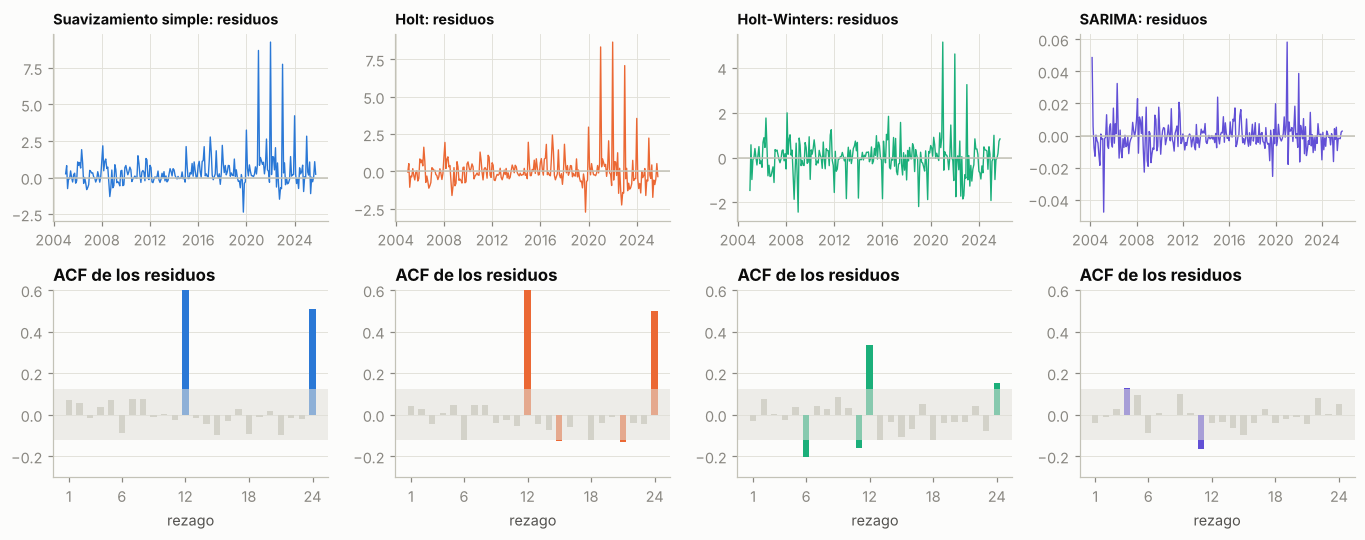

Mayores residuos de SARIMA (en %): {'2021-01': 5.8, '2004-03': 4.9, '2005-03': 4.8, '2022-01': 3.9, '2006-05': 3.2}


In [10]:
diag = pd.DataFrame([{"modelo": M.ETIQUETA[n], **M.diagnostico_residuos(ajustes[n]["residuos"], ajustes[n]["n_param"])} for n in M.MODELOS]).set_index("modelo")
display(diag)
fig, axs = plt.subplots(2, 4, figsize=(12.5, 5))
for j, n in enumerate(("ses", "holt", "holt_winters", "sarima")):
    r = ajustes[n]["residuos"]; axs[0, j].plot(r, color=COLOR[n], lw=0.9); axs[0, j].axhline(0, color="#c3c2b7", lw=1); axs[0, j].set_title(f"{M.ETIQUETA[n]}: residuos", fontsize=9.5)
    ar = acf(r, nlags=24); lim = 1.96 / np.sqrt(len(r)); k = np.arange(1, 25)
    axs[1, j].bar(k, ar[1:], color=[COLOR[n] if abs(v) > lim else "#c3c2b7" for v in ar[1:]], width=0.6); axs[1, j].axhspan(-lim, lim, color="#e1e0d9", alpha=0.55, lw=0)
    axs[1, j].set(title="ACF de los residuos", xlabel="rezago", xticks=[1, 6, 12, 18, 24], ylim=(-0.3, 0.6)); axs[1, j].title.set_fontsize(9.5); axs[1, j].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
s_res = ajustes["sarima"]["residuos"]; print("Mayores residuos de SARIMA (en %):", {f"{k:%Y-%m}": round(v * 100, 1) for k, v in s_res.abs().sort_values(ascending=False).head(5).items()})

**Lectura.**

- **Suavizamiento simple, Holt y las dos referencias fallan con claridad**: la ACF de sus residuos tiene barras enormes en los rezagos 12 y 24 (cerca de 0.6 y 0.45). Es el escalón de enero: cada año se equivocan en el mismo mes y por el mismo lado. Dejan información sin usar.
- **Holt-Winters mejora** (baja esa barra a la mitad) pero sigue rechazando Ljung-Box: su patrón estacional es fijo (γ ≈ 0) y el escalón de enero ha crecido desde 2021.
- **SARIMA es el que más se acerca al ruido blanco:** elimina la autocorrelación de los rezagos 12 y 24, solo dos barras quedan apenas fuera de la banda, y **pasa Ljung-Box a 24 rezagos**, pero **no a 12** con la corrección de grados de libertad (valor p cercano a 0.01). Con los criterios fijados antes de ver los datos, **ningún modelo cumple del todo**.
- **Ninguno tiene residuos normales** (Jarque-Bera rechaza en todos): los residuos más grandes caen en los meses de choque de precios. No es un problema del promedio del pronóstico, sino de sus intervalos, que resultan demasiado estrechos en épocas de choque.

**¿Existe un SARIMA que sí pase?** Se amplió la búsqueda a p y q hasta 3 (64 modelos). Solo uno pasa Ljung-Box en los dos rezagos, el (3,1,3)(1,0,1)₁₂. La celda siguiente lo compara con el elegido.

In [11]:
alt = ((3, 1, 3), (1, 0, 1, 12)); m_alt = M.ajustar("sarima", ent, alt)
comp = pd.DataFrame([{"modelo": f"SARIMA {o}{e[:3]}", "parámetros": m["n_param"], "AIC": m["parametros"]["AIC"], **{k: v for k, v in M.diagnostico_residuos(m["residuos"], m["n_param"]).items() if k.startswith("p LB")}}
    for (o, e), m in (((orden, estacional), ajustes["sarima"]), (alt, m_alt))]).set_index("modelo")
vc_alt = M.resumen_validacion(M.validacion_origen_movil(y, origenes=36, sarima=alt, modelos=["sarima"])).set_index("h").MAPE_pct
vc_ele = res[res.modelo == "sarima"].set_index("h").MAPE_pct
for h in (1, 3, 6, 12): comp[f"MAPE % h={h}"] = [vc_ele[h], vc_alt[h]]
display(comp)

,parámetros,AIC,p LB(12),p LB(24),MAPE % h=1,MAPE % h=3,MAPE % h=6,MAPE % h=12
modelo,,,,,,,,
"SARIMA (1, 1, 0)(1, 0, 1)",4,"-1,651.018",0.009,0.085,0.465,1.122,1.785,3.326
"SARIMA (3, 1, 3)(1, 0, 1)",9,"-1,647.924",0.070,0.237,0.434,1.115,1.557,3.028


El modelo (3,1,3)(1,0,1)₁₂ pasa las dos pruebas (por poco a 12 rezagos) y su error de validación es ligeramente menor. Aun así **se conserva el modelo simple** por tres razones: tiene el doble de parámetros y peor AIC, la mejora en error es pequeña (centésimas a 1 y 3 meses, décimas a 6 y 12), y es el único de 64 candidatos que pasa. Elegir el modelo después de ver cuál pasa el diagnóstico es ajustar el modelo a la prueba. Queda como candidato a confirmar cuando haya meses nuevos.

Lo que queda por modelar no es tanto dependencia lineal como **varianza que cambia en el tiempo** y **choques puntuales**; eso se atiende con variables de intervención o un modelo de volatilidad. Queda como trabajo de E2.

## 6. Pronóstico y conclusiones

,pronóstico,IC 80 % inf,IC 80 % sup,IC 95 % inf,IC 95 % sup,variación anual %
2026-11,163.424,161.388,165.486,160.321,166.588,6.644
2026-12,163.915,160.553,167.347,158.801,169.193,6.466
2027-01,167.086,162.588,171.709,160.256,174.207,6.903
2027-02,167.824,162.413,173.415,159.619,176.450,6.720
2027-03,168.668,162.455,175.118,159.260,178.631,6.348
2027-04,169.924,162.974,177.170,159.411,181.130,5.662
2027-05,170.250,162.660,178.193,158.780,182.548,5.222
2027-06,170.846,162.651,179.453,158.474,184.183,5.210
2027-07,171.082,162.338,180.296,157.892,185.373,5.258
2027-08,171.226,161.970,181.011,157.275,186.415,5.748


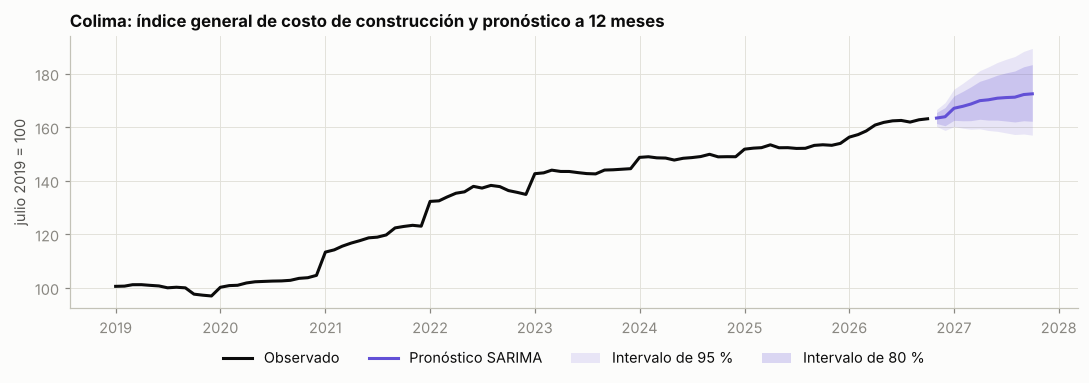

Último dato (2026-10): 163.2 | pronóstico a 12 meses (2027-10): 172.5, IC 95 % de 157.0 a 189.4


In [12]:
final = M.ajustar("sarima", y, (orden, estacional)); h = 12
p = final["pronosticar"](h); ic80 = final["intervalo"](h, 0.20); ic95 = final["intervalo"](h, 0.05)
tab = pd.DataFrame({"pronóstico": p, "IC 80 % inf": ic80.iloc[:, 0], "IC 80 % sup": ic80.iloc[:, 1], "IC 95 % inf": ic95.iloc[:, 0], "IC 95 % sup": ic95.iloc[:, 1]})
tab["variación anual %"] = (p.to_numpy() / y.iloc[-12:].to_numpy() - 1) * 100; tab.index = tab.index.strftime("%Y-%m"); display(tab)
fig, ax = plt.subplots(figsize=(10, 3.6)); ax.plot(y["2019-01-01":], color="#0b0b0b", label="Observado"); ax.plot(p, color="#6250d6", label="Pronóstico SARIMA")
ax.fill_between(p.index, ic95.iloc[:, 0], ic95.iloc[:, 1], color="#6250d6", alpha=0.13, lw=0, label="Intervalo de 95 %"); ax.fill_between(p.index, ic80.iloc[:, 0], ic80.iloc[:, 1], color="#6250d6", alpha=0.22, lw=0, label="Intervalo de 80 %")
ax.set(title="Colima: índice general de costo de construcción y pronóstico a 12 meses", ylabel="julio 2019 = 100"); ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1)); plt.tight_layout(); plt.show()
print(f"Último dato ({y.index[-1]:%Y-%m}): {y.iloc[-1]:.1f} | pronóstico a 12 meses ({p.index[-1]:%Y-%m}): {p.iloc[-1]:.1f}, IC 95 % de {ic95.iloc[-1, 0]:.1f} a {ic95.iloc[-1, 1]:.1f}")

### Conclusiones

1. **La serie no es estacionaria en nivel y sí lo es su variación mensual** (ADF y KPSS coinciden). Tiene tendencia dominante, un escalón cada enero y choques que cambian su volatilidad.
2. **Para 1 a 3 meses: SARIMA sobre el logaritmo.** Tiene el menor error en la validación de 36 orígenes, los residuos más cercanos al ruido blanco y, en esta implementación, es el único de los cuatro que entrega intervalos de confianza. Es el modelo del pronóstico mostrado arriba.
3. **Para 6 a 12 meses: Holt-Winters.** Menor error y casi sin sesgo en Colima. SARIMA tiende a pronosticar de más a un año.
4. **Precisión esperada en Colima:** alrededor de 0.5 % de error a un mes y 1.1 % a tres (SARIMA); 1.4 % a seis y 2.3 % a doce (Holt-Winters).
5. **El suavizamiento simple no aporta nada sobre repetir el último valor** en esta serie, y Holt es riesgoso después de un choque.

### Limitaciones

- **Los residuos del SARIMA elegido no pasan Ljung-Box a 12 rezagos** y no son normales: los intervalos mostrados son demasiado optimistas en épocas de choque de precios.
- **Las conclusiones a 12 meses dependen del periodo de validación.** Este análisis se corrió primero con datos hasta julio de 2025 (antes de localizar la estructura vigente del índice): ahí SARIMA también ganaba a 1 y 3 meses, pero a 12 meses ningún modelo superaba con claridad a la referencia de deriva. Con 15 meses más de datos, Holt-Winters pasa a ganar a 12 meses. Lo estable es el resultado de corto plazo.
- Solo se modeló el índice general de una ciudad y el Nacional. Falta repetirlo por componente y para las 46 ciudades.
- No se usaron variables explicativas (tipo de cambio, salario mínimo). Mano de obra, que cambia por escalones, probablemente se pronostica mejor con el calendario de aumentos salariales que con un modelo de series de tiempo.